# Estudo de Caso 7.1 — Infiltração em Meio Poroso: Comparação dos Modelos de Darcy, Forchheimer e Brinkman

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 7 — Formulação Diferencial e Equações de Navier-Stokes |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 60 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Solução analítica (Darcy/Forchheimer/Ergun) + Diferenças Finitas com solver tridiagonal (`scipy.linalg.solve_banded`) para o BVP de Brinkman |
| **Bibliografia** | Bear (1972), Cap. 4–5; Forchheimer (1901); Brinkman (1947); Ergun (1952); Livro Vol. I, Cap. 7, Seções 7.6–7.7 |

---

## 📋 Resumo

Este estudo de caso calcula o fluxo de infiltração/percolação em meios porosos sob gradiente motriz prescrito, comparando os três fechamentos derivados da média volumétrica de Navier-Stokes: **Darcy** (linear, $Re_g < 1$), **Forchheimer** (correção inercial quadrática, $1 < Re_g < 100$) e **Brinkman** (camada de transição próxima a paredes, com perfil de velocidade resolvido por diferenças finitas). A principal métrica de resultado é a redução do fluxo predito em relação à Lei de Darcy ("pedágio inercial" e efeito de parede), diagnosticada pelo número de Reynolds de grão $Re_g$.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Aplicar** as leis de Darcy, Forchheimer e Ergun para calcular o fluxo de infiltração sob gradiente motriz prescrito.
2. **Implementar** a raiz física da equação quadrática de Forchheimer e a discretização por diferenças finitas da equação de Brinkman com solver tridiagonal.
3. **Verificar** os limites assintóticos de cada modelo (Forchheimer $\to$ Darcy quando $\beta \to 0$; Brinkman $\to$ Darcy e $\to$ Poiseuille).
4. **Calcular** o número de Reynolds de grão $Re_g$ e classificar o regime de escoamento no meio poroso.
5. **Comparar** perfis de velocidade e fluxos médios entre os modelos, quantificando a espessura da camada de Brinkman $\lambda$.
6. **Analisar** a sensibilidade do fluxo à permeabilidade $k$ e a convergência de malha do esquema de diferenças finitas.
7. **Interpretar** a hierarquia de modelos de meio poroso no contexto da média volumétrica de Navier-Stokes (Cap. 7).

---

## ⚙️ Seção 0: Configuração Inicial

In [16]:
# ============================================================
# CONFIGURAÇÃO INICIAL
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from IPython.display import display, Markdown

# Compatibilidade NumPy 1.x / 2.x: np.trapz foi removido no NumPy 2.0
# e renomeado para np.trapezoid. O alias garante execução em ambos.
_trapz = getattr(np, "trapezoid", None) or getattr(np, "trapz")

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

---

## 🌊 Seção 1: Parâmetros do Fluido e do Meio Poroso

Dois meios são considerados: **(i)** uma areia grossa (`MEIO`), usada na comparação Darcy $\times$ Forchheimer $\times$ Ergun; **(ii)** uma camada drenante muito permeável (`MEIO_B`), usada no problema de valor de contorno de Brinkman (interface solo–dreno confinada entre paredes impermeáveis).

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|:-----:|:-------:|
| Massa específica da água | $\rho$ | 998 | kg/m³ |
| Viscosidade dinâmica | $\mu$ | 1,0 × 10⁻³ | Pa·s |
| Permeabilidade intrínseca (areia) | $k$ | 1,0 × 10⁻⁹ | m² |
| Porosidade | $\eta$ | 0,35 | – |
| Diâmetro do grão (areia) | $d_g$ | 1,0 × 10⁻³ | m |
| Coeficiente de Forchheimer | $\beta$ | 1,0 × 10⁴ | m⁻¹ |
| Permeabilidade (camada drenante) | $k_B$ | 1,0 × 10⁻⁶ | m² |
| Semi-espessura da camada (Brinkman) | $H$ | 0,02 | m |
| Viscosidade efetiva | $\mu_{eff} = \mu/\eta$ | 2,857 × 10⁻³ | Pa·s |
| Gradiente motriz (infiltração, $i=1$) | $G = \rho g$ | 9,79 × 10³ | Pa/m |

In [17]:
# ============================================================
# PARÂMETROS DO FLUIDO E DO MEIO POROSO
# ============================================================
g = 9.81                      # Aceleração gravitacional [m/s²]

FLUIDO = dict(
    rho=998.0,                # Massa específica da água [kg/m³]
    mu=1.0e-3,                # Viscosidade dinâmica [Pa·s]
)

MEIO = dict(                  # Areia grossa (Darcy vs Forchheimer)
    k=1.0e-9,                 # Permeabilidade intrínseca [m²]
    eta=0.35,                 # Porosidade [-]
    dg=1.0e-3,                # Diâmetro característico do grão [m]
    beta=1.0e-4 * 1.0e8,      # Coeficiente de Forchheimer [1/m] (=1e4)
)

MEIO_B = dict(                # Camada drenante (BVP de Brinkman)
    k=1.0e-6,                 # Permeabilidade intrínseca [m²]
    eta=0.35,                 # Porosidade [-]
    dg=5.0e-3,                # Diâmetro característico do grão [m]
    beta=1.0e2,               # Coeficiente de Forchheimer [1/m] (não usado aqui)
)

H = 0.02                      # Semi-espessura da camada porosa confinada [m]
N_NOS = 401                   # Número de nós da malha de Brinkman [-]
G_UNIT = FLUIDO["rho"] * g    # Gradiente motriz para gradiente hidráulico unitário [Pa/m]

print("=" * 60)
print(" PARÂMETROS DO FLUIDO E DO MEIO POROSO")
print("=" * 60)
print(f"\n💧 Fluido (água a 20 °C):")
print(f"  • ρ = {FLUIDO['rho']:.1f} kg/m³ | μ = {FLUIDO['mu']:.1e} Pa·s")
print(f"\n🪨 Meio 1 — areia grossa (Darcy/Forchheimer/Ergun):")
print(f"  • k = {MEIO['k']:.1e} m² | η = {MEIO['eta']} | d_g = {MEIO['dg']:.1e} m | β = {MEIO['beta']:.1e} 1/m")
print(f"\n🪨 Meio 2 — camada drenante (Brinkman):")
print(f"  • k_B = {MEIO_B['k']:.1e} m² | H = {H} m | μ_eff = {FLUIDO['mu']/MEIO_B['eta']:.3e} Pa·s")
print(f"\n🌧️ Forçamento de referência: G = ρg = {G_UNIT:.2e} Pa/m (i = 1)")

 PARÂMETROS DO FLUIDO E DO MEIO POROSO

💧 Fluido (água a 20 °C):
  • ρ = 998.0 kg/m³ | μ = 1.0e-03 Pa·s

🪨 Meio 1 — areia grossa (Darcy/Forchheimer/Ergun):
  • k = 1.0e-09 m² | η = 0.35 | d_g = 1.0e-03 m | β = 1.0e+04 1/m

🪨 Meio 2 — camada drenante (Brinkman):
  • k_B = 1.0e-06 m² | H = 0.02 m | μ_eff = 2.857e-03 Pa·s

🌧️ Forçamento de referência: G = ρg = 9.79e+03 Pa/m (i = 1)


---

## 🔬 Seção 2: Verificação / Validação

Antes da simulação principal, verificamos a consistência física e numérica dos modelos:

1. **Limite $\beta \to 0$:** Forchheimer deve colapsar na Lei de Darcy (erro relativo < 0,01 %).
2. **Desigualdade física:** o fluxo de Forchheimer deve ser menor que o de Darcy ($q_F < q_D$), pois o termo inercial é dissipativo.
3. **Limite $k \to \infty$ (Brinkman $\to$ Poiseuille):** o perfil numérico deve reproduzir $u(y) = G(H^2 - y^2)/(2\mu_{eff})$.
4. **Consistência analítico $\times$ numérico:** o esquema de diferenças finitas deve reproduzir a solução analítica de Brinkman com erro < 1 %.

> 📖 **Referência:** Bear (1972), Cap. 4; Livro Vol. I, Cap. 7, Seção 7.7 (Tabela 7.1).

In [18]:
# ============================================================
# VERIFICAÇÃO / VALIDAÇÃO (funções definidas aqui p/ uso imediato)
# ============================================================
def q_darcy(G, p=MEIO, f=FLUIDO):
    """Lei de Darcy: q = (k/mu) * G.

    Parameters
    ----------
    G : float ou np.ndarray
        Gradiente motriz (pressão + gravidade) [Pa/m].
    p : dict
        Parâmetros do meio (k [m²], eta [-]).
    f : dict
        Parâmetros do fluido (rho [kg/m³], mu [Pa·s]).

    Returns
    -------
    float ou np.ndarray
        Fluxo de Darcy [m/s].
    """
    return p["k"] * np.asarray(G, dtype=float) / f["mu"]


def q_forchheimer(G, p=MEIO, f=FLUIDO):
    """Raiz física da equação quadrática de Forchheimer.

    beta*rho*q^2 + (mu/k)*q - G = 0  =>  q = (-b + sqrt(b^2 + 4*a*G)) / (2*a)

    Parameters
    ----------
    G : float ou np.ndarray
        Gradiente motriz [Pa/m].
    p : dict
        Parâmetros do meio (k [m²], beta [1/m]).
    f : dict
        Parâmetros do fluido (rho [kg/m³], mu [Pa·s]).

    Returns
    -------
    float ou np.ndarray
        Fluxo de Forchheimer [m/s].
    """
    a = p["beta"] * f["rho"]                 # Coeficiente inercial [kg/m⁴]
    b = f["mu"] / p["k"]                     # Coeficiente viscoso [Pa·s/m²]
    G = np.asarray(G, dtype=float)
    return (-b + np.sqrt(b**2 + 4.0 * a * G)) / (2.0 * a)


print("=" * 60)
print(" VERIFICAÇÃO PRÉVIA")
print("=" * 60)

# Verificação 1: Forchheimer -> Darcy quando beta -> 0
p_beta0 = dict(MEIO, beta=1.0)
erro_beta0 = abs(q_forchheimer(G_UNIT, p_beta0) - q_darcy(G_UNIT)) / q_darcy(G_UNIT)
assert erro_beta0 < 1e-4, f"❌ Limite beta->0 falhou (erro = {erro_beta0:.2e})"
print(f"✅ Verificação 1: β→0 ⇒ Forchheimer ≡ Darcy (erro = {erro_beta0:.2e}).")

# Verificação 2: q_F < q_D (termo inercial é dissipativo)
assert q_forchheimer(G_UNIT) < q_darcy(G_UNIT), "❌ q_F >= q_D: inconsistência física"
print(f"✅ Verificação 2: q_F = {q_forchheimer(G_UNIT):.4e} < q_D = {q_darcy(G_UNIT):.4e} m/s.")

# Verificação 3: Brinkman -> Poiseuille quando k -> infinito
p_kinf = dict(MEIO_B, k=1.0)                       # k enorme => meio sem poros
mu_eff = FLUIDO["mu"] / p_kinf["eta"]              # Viscosidade efetiva [Pa·s]
y_test = np.linspace(-H, H, 201)                   # Malha de teste [m]
lam_t = np.sqrt(mu_eff * p_kinf["k"] / FLUIDO["mu"])
uD_t = G_UNIT * p_kinf["k"] / FLUIDO["mu"]
u_ana_t = uD_t * (1.0 - np.cosh(y_test / lam_t) / np.cosh(H / lam_t))
u_pois = G_UNIT * (H**2 - y_test**2) / (2.0 * mu_eff)   # Poiseuille com mu_eff [m/s]
erro_pois = np.max(np.abs(u_ana_t - u_pois)) / np.max(np.abs(u_pois))
assert erro_pois < 1e-2, f"❌ Limite Poiseuille falhou (erro = {erro_pois:.2e})"
print(f"✅ Verificação 3: k→∞ ⇒ Brinkman ≡ Poiseuille (erro = {erro_pois:.2e}).")

# Verificação 4: analítico x numérico (definido na Seção 6; executado aqui via função local)
def _brinkman_numerico(G, H, N, p, f):
    """Discretização MFV/DIF centrais do BVP de Brinkman (solver tridiagonal)."""
    mu_eff = f["mu"] / p["eta"]
    y = np.linspace(-H, H, N)
    dy = y[1] - y[0]
    n = N - 2
    ab = np.zeros((3, n))
    ab[0, 1:] = mu_eff / dy**2                     # Superdiagonal [Pa·s/m² / m²]
    ab[1, :] = -2.0 * mu_eff / dy**2 - f["mu"] / p["k"]   # Diagonal principal
    ab[2, :-1] = mu_eff / dy**2                    # Subdiagonal
    b = np.full(n, -G)                             # Termo fonte (gradiente motriz)
    u_int = solve_banded((1, 1), ab, b)
    return y, np.concatenate(([0.0], u_int, [0.0]))

def _brinkman_analitico(y, G, H, p, f):
    """Solução analítica do BVP de Brinkman: u = uD*(1 - cosh(y/lam)/cosh(H/lam))."""
    mu_eff = f["mu"] / p["eta"]
    lam = np.sqrt(mu_eff * p["k"] / f["mu"])
    uD = G * p["k"] / f["mu"]
    return uD * (1.0 - np.cosh(y / lam) / np.cosh(H / lam)), lam, uD

y_v, u_num_v = _brinkman_numerico(G_UNIT, H, N_NOS, MEIO_B, FLUIDO)
u_ana_v, lam_v, uD_v = _brinkman_analitico(y_v, G_UNIT, H, MEIO_B, FLUIDO)
erro_bn = np.max(np.abs(u_num_v - u_ana_v)) / np.max(np.abs(u_ana_v))
assert erro_bn < 1e-2, f"❌ MDF vs analítico falhou (erro = {erro_bn:.2e})"
print(f"✅ Verificação 4: MDF (N={N_NOS}) ≡ analítico (erro = {erro_bn:.2e}).")
print("\n✅ Todas as verificações foram aprovadas!")

 VERIFICAÇÃO PRÉVIA
✅ Verificação 1: β→0 ⇒ Forchheimer ≡ Darcy (erro = 9.77e-06).
✅ Verificação 2: q_F = 8.9847e-03 < q_D = 9.7904e-03 m/s.
✅ Verificação 3: k→∞ ⇒ Brinkman ≡ Poiseuille (erro = 5.83e-05).
✅ Verificação 4: MDF (N=401) ≡ analítico (erro = 5.36e-05).

✅ Todas as verificações foram aprovadas!


---

## 📐 Seção 3: Formulação Matemática

### 3.1 Lei de Darcy (regime *creeping*, $Re_g < 1$)

$$q = \frac{k}{\mu}\, G \qquad\text{com}\qquad G \equiv -\nabla p + \rho \mathbf{g}$$

onde $q$ = fluxo de Darcy [m/s], $k$ = permeabilidade intrínseca [m²], $\mu$ = viscosidade dinâmica [Pa·s] e $G$ = gradiente motriz [Pa/m]. Para infiltração vertical com gradiente hidráulico unitário, $G = \rho g$.

### 3.2 Equação de Forchheimer (regime inercial, $1 < Re_g < 100$)

$$\beta \rho\, |q|\, q + \frac{\mu}{k}\, q - G = 0 \;\;\Rightarrow\;\; q = \frac{-b + \sqrt{b^2 + 4 a G}}{2a},\quad a = \beta\rho,\; b = \mu/k$$

onde $\beta$ = coeficiente de Forchheimer [m⁻¹] e $\rho$ = massa específica [kg/m³]. A raiz positiva é a única fisicamente admissível.

### 3.3 Equação de Brinkman (camada de transição, BVP 1D)

$$\mu_{eff}\,\frac{d^2 u}{dy^2} - \frac{\mu}{k}\, u + G = 0,\qquad u(\pm H) = 0$$

Solução analítica: $u(y) = u_D\left[1 - \dfrac{\cosh(y/\lambda)}{\cosh(H/\lambda)}\right]$, com $u_D = \dfrac{G k}{\mu}$ [m/s] e camada de Brinkman $\lambda = \sqrt{\dfrac{\mu_{eff}\, k}{\mu}}$ [m]. O fluxo médio é $q_B = u_D\left[1 - \dfrac{\lambda}{H}\tanh\!\left(\dfrac{H}{\lambda}\right)\right]$ [m/s].

### 3.4 Diagnóstico de regime (número de Reynolds de grão)

$$Re_g = \frac{\rho\, u_{poro}\, d_g}{\mu},\qquad u_{poro} = \frac{q}{\eta}$$

### 3.5 Equação de Ergun (referência, $Re_g > 100$)

$$G = 150\,\frac{(1-\eta)^2}{\eta^3}\frac{\mu}{d_g^2}\, q + 1{,}75\,\frac{1-\eta}{\eta^3}\frac{\rho}{d_g}\, q^2$$

### Condições de contorno (Brinkman)

| Tipo | Localização | Condição | Justificativa |
|:-----|:-----------|:---------|:--------------|
| Dirichlet | $y = \pm H$ (paredes) | $u = 0$ | Não-deslizamento em fronteira impermeável |
| Simetria (implícita) | $y = 0$ (centro) | $du/dy = 0$ | Perfil simétrico recuperado pela solução |

> 📖 **Referência:** Bear (1972), Cap. 4–5; Forchheimer (1901); Brinkman (1947); Ergun (1952); Livro Vol. I, Cap. 7, Eqs. 7.6–7.16.

---

## ⚡ Seção 4: Estabilidade / Critério Numérico

O problema de Brinkman é um **BVP estacionário**: não há condição CFL (não há marcha temporal). Os critérios numéricos relevantes são:

| Critério | Valor | Justificativa |
|:---------|:-----:|:--------------|
| Número de nós ($N$) | 401 | Resolução $\Delta y = 1{,}0 \times 10^{-4}$ m |
| Resolução da camada de Brinkman | $\Delta y / \lambda \leq 1/3$ | Capturar o decaimento $\cosh$ perto das paredes |
| Diagonal dominante | sempre | $\lvert a_P \rvert = 2\mu_{eff}/\Delta y^2 + \mu/k > 2\mu_{eff}/\Delta y^2$ ⇒ `solve_banded` estável sem pivotamento |
| Solver | `solve_banded` | Sistema tridiagonal, custo $O(N)$ |

> 💡 **Observação:** em esquemas explícitos *transientes* a condição CFL seria obrigatória; aqui o análogo é a resolução da escala $\lambda$, que é a "camada limite" do meio poroso.

In [19]:
# ============================================================
# CRITÉRIOS NUMÉRICOS (BVP DE BRINKMAN)
# ============================================================
mu_eff_B = FLUIDO["mu"] / MEIO_B["eta"]            # Viscosidade efetiva [Pa·s]
lam_B = np.sqrt(mu_eff_B * MEIO_B["k"] / FLUIDO["mu"])   # Camada de Brinkman [m]
dy = 2.0 * H / (N_NOS - 1)                         # Espaçamento da malha [m]

print("=" * 60)
print(" CRITÉRIOS NUMÉRICOS")
print("=" * 60)
print(f"\n📏 Discretização:")
print(f"  • Número de nós: N = {N_NOS}")
print(f"  • Espaçamento: Δy = {dy:.2e} m")
print(f"  • Domínio: y ∈ [-{H}, {H}] m")
print(f"\n⚡ Resolução da camada de Brinkman:")
print(f"  • λ = {lam_B*1e3:.3f} mm | H/λ = {H/lam_B:.1f}")
print(f"  • Δy/λ = {dy/lam_B:.3f} (critério: ≤ 0.333)")
assert dy / lam_B <= 1.0 / 3.0, "❌ Malha grossa demais para resolver λ"
print(f"\n🔧 Solver: scipy.linalg.solve_banded (tridiagonal, O(N))")
print(f"  • Diagonal dominante: |aP| = {2*mu_eff_B/dy**2 + FLUIDO['mu']/MEIO_B['k']:.3e} "
      f"> {2*mu_eff_B/dy**2:.3e} ✓")
print(f"\n⚡ Nota: não há condição CFL (problema estacionário).")

 CRITÉRIOS NUMÉRICOS

📏 Discretização:
  • Número de nós: N = 401
  • Espaçamento: Δy = 1.00e-04 m
  • Domínio: y ∈ [-0.02, 0.02] m

⚡ Resolução da camada de Brinkman:
  • λ = 1.690 mm | H/λ = 11.8
  • Δy/λ = 0.059 (critério: ≤ 0.333)

🔧 Solver: scipy.linalg.solve_banded (tridiagonal, O(N))
  • Diagonal dominante: |aP| = 5.724e+05 > 5.714e+05 ✓

⚡ Nota: não há condição CFL (problema estacionário).


---

## 🌪️ Seção 5: Forçamento / Condição de Entrada

O **forçamento** é o gradiente motriz $G$ [Pa/m], que representa a soma do gradiente de pressão e do termo gravitacional. Quatro cenários de engenharia são considerados:

| Caso | $G$ [Pa/m] | Justificativa física |
|:-----|:----------:|:---------------------|
| Infiltração natural ($i=1$) | 9,79 × 10³ | Recarga natural, gradiente hidráulico unitário |
| Vala de infiltração | 1,0 × 10⁴ | Lâmina d'água rasa sobre o solo |
| Vazamento sob pressão | 1,0 × 10⁵ | Tubulação enterrada com sobrepressão |
| Poço de bombeamento | 1,0 × 10⁶ | Gradiente elevado próximo ao filtro |

Para o BVP de Brinkman adota-se $G = \rho g$ (infiltração natural) em camada drenante confinada.

> 💡 **Observação:** $G = 10^6$ Pa/m em areia grossa produz $q \sim 1$ m/s e $Re_g > 10^3$, entrando no regime de Ergun — útil para delimitar a validade de Forchheimer.

In [20]:
# ============================================================
# FORÇAMENTO / CONDIÇÃO DE ENTRADA
# ============================================================
CASOS = {
    "Infiltração natural (i=1)": G_UNIT,
    "Vala de infiltração":       1.0e4,
    "Vazamento sob pressão":     1.0e5,
    "Poço de bombeamento":       1.0e6,
}

print("=" * 60)
print(" FORÇAMENTO (GRADIENTE MOTRIZ G)")
print("=" * 60)
for nome, Gv in CASOS.items():
    q_ref = q_darcy(Gv)
    print(f"\n🌧️ {nome}:")
    print(f"  • G = {Gv:.2e} Pa/m")
    print(f"  • q_Darcy = {q_ref:.3e} m/s ({q_ref*86400:.1f} m/dia)")

 FORÇAMENTO (GRADIENTE MOTRIZ G)

🌧️ Infiltração natural (i=1):
  • G = 9.79e+03 Pa/m
  • q_Darcy = 9.790e-03 m/s (845.9 m/dia)

🌧️ Vala de infiltração:
  • G = 1.00e+04 Pa/m
  • q_Darcy = 1.000e-02 m/s (864.0 m/dia)

🌧️ Vazamento sob pressão:
  • G = 1.00e+05 Pa/m
  • q_Darcy = 1.000e-01 m/s (8640.0 m/dia)

🌧️ Poço de bombeamento:
  • G = 1.00e+06 Pa/m
  • q_Darcy = 1.000e+00 m/s (86400.0 m/dia)


---

## 🧮 Seção 6: Implementação Numérica

### 6.1 Funções de fluxo (Darcy, Forchheimer, Ergun) e diagnóstico $Re_g$
### 6.2 BVP de Brinkman: diferenças finitas centrais + `solve_banded`
### 6.3 Execução para todos os casos de forçamento

In [21]:
# ============================================================
# 6.1 FUNÇÕES DE FLUXO E DIAGNÓSTICO DE REGIME
# ============================================================
def q_ergun(G, p=MEIO, f=FLUIDO):
    """Equação de Ergun (leito empacotado, Re_g > 100).

    Parameters
    ----------
    G : float ou np.ndarray
        Gradiente motriz [Pa/m].
    p : dict
        Parâmetros do meio (k não usado; eta [-], dg [m]).
    f : dict
        Parâmetros do fluido (rho [kg/m³], mu [Pa·s]).

    Returns
    -------
    float ou np.ndarray
        Fluxo [m/s].
    """
    a = 1.75 * (1 - p["eta"]) / p["eta"]**3 * f["rho"] / p["dg"]    # Coef. inercial [kg/m⁴]
    b = 150.0 * (1 - p["eta"])**2 / p["eta"]**3 * f["mu"] / p["dg"]**2  # Coef. viscoso [Pa·s/m²]
    G = np.asarray(G, dtype=float)
    return (-b + np.sqrt(b**2 + 4.0 * a * G)) / (2.0 * a)


def re_grao(q, p=MEIO, f=FLUIDO):
    """Número de Reynolds de grão com velocidade intersticial u = q/eta.

    Parameters
    ----------
    q : float ou np.ndarray
        Fluxo de Darcy [m/s].
    p : dict
        Parâmetros do meio (eta [-], dg [m]).
    f : dict
        Parâmetros do fluido (rho [kg/m³], mu [Pa·s]).

    Returns
    -------
    float ou np.ndarray
        Re_g [-].
    """
    return f["rho"] * (np.asarray(q, dtype=float) / p["eta"]) * p["dg"] / f["mu"]


def modelo_recomendado(Re):
    """Classifica o regime pelo Re_g (Tabela 7.1 do Livro Vol. I).

    Parameters
    ----------
    Re : float
        Número de Reynolds de grão [-].

    Returns
    -------
    str
        Modelo recomendado: 'Darcy', 'Forchheimer' ou 'Turbulento (Ergun)'.
    """
    if Re < 1.0:
        return "Darcy"
    if Re <= 100.0:
        return "Forchheimer"
    return "Turbulento (Ergun)"


print("✅ Funções de fluxo (Darcy/Forchheimer/Ergun) e Re_g implementadas.")

✅ Funções de fluxo (Darcy/Forchheimer/Ergun) e Re_g implementadas.


In [22]:
# ============================================================
# 6.2 BVP DE BRINKMAN: DIFERENÇAS FINITAS + SOLVE_BANDED
# ============================================================
def brinkman_numerico(G, H, N, p=MEIO_B, f=FLUIDO):
    """Resolve o BVP de Brinkman por diferenças finitas centrais.

    mu_eff*u'' - (mu/k)*u + G = 0, u(±H) = 0.

    Parameters
    ----------
    G : float
        Gradiente motriz [Pa/m].
    H : float
        Semi-espessura da camada [m].
    N : int
        Número de nós [-].
    p : dict
        Parâmetros do meio (k [m²], eta [-]).
    f : dict
        Parâmetros do fluido (mu [Pa·s]).

    Returns
    -------
    y : np.ndarray
        Coordenada transversal [m].
    u : np.ndarray
        Perfil de velocidade [m/s].
    """
    mu_eff = f["mu"] / p["eta"]                    # Viscosidade efetiva [Pa·s]
    y = np.linspace(-H, H, N)                      # Malha [m]
    dy = y[1] - y[0]                               # Passo [m]
    n = N - 2                                      # Nós internos [-]
    ab = np.zeros((3, n))                          # Matriz em formato banda (3, n)
    ab[0, 1:] = mu_eff / dy**2                     # Superdiagonal (a_E)
    ab[1, :] = -2.0 * mu_eff / dy**2 - f["mu"] / p["k"]   # Diagonal (a_P)
    ab[2, :-1] = mu_eff / dy**2                    # Subdiagonal (a_W)
    b = np.full(n, -G)                             # Vetor fonte [-G]
    u_int = solve_banded((1, 1), ab, b)            # Solver tridiagonal O(N)
    u = np.concatenate(([0.0], u_int, [0.0]))      # CC de não-deslizamento u(±H)=0
    return y, u


def brinkman_analitico(y, G, H, p=MEIO_B, f=FLUIDO):
    """Solução analítica do BVP de Brinkman.

    Parameters
    ----------
    y : np.ndarray
        Coordenada transversal [m].
    G : float
        Gradiente motriz [Pa/m].
    H : float
        Semi-espessura [m].
    p : dict
        Parâmetros do meio (k [m²], eta [-]).
    f : dict
        Parâmetros do fluido (mu [Pa·s]).

    Returns
    -------
    u : np.ndarray
        Perfil de velocidade [m/s].
    lam : float
        Espessura da camada de Brinkman [m].
    uD : float
        Velocidade de plug de Darcy [m/s].
    """
    mu_eff = f["mu"] / p["eta"]
    lam = np.sqrt(mu_eff * p["k"] / f["mu"])       # Camada de Brinkman [m]
    uD = G * p["k"] / f["mu"]                      # Plug de Darcy [m/s]
    u = uD * (1.0 - np.cosh(y / lam) / np.cosh(H / lam))
    return u, lam, uD


print("✅ BVP de Brinkman implementado (MDF + solve_banded e analítico).")

✅ BVP de Brinkman implementado (MDF + solve_banded e analítico).


In [24]:
# ============================================================
# 6.3 EXECUÇÃO PARA TODOS OS CASOS DE FORÇAMENTO
# ============================================================
resultados = {}
for nome, Gv in CASOS.items():
    t0 = time.time()
    qD = float(q_darcy(Gv))                        # Fluxo de Darcy [m/s]
    qF = float(q_forchheimer(Gv))                  # Fluxo de Forchheimer [m/s]
    qE = float(q_ergun(Gv))                        # Fluxo de Ergun [m/s]
    Re = float(re_grao(qF))                        # Re_g com fluxo de Forchheimer [-]
    resultados[nome] = dict(G=Gv, qD=qD, qF=qF, qE=qE, Re=Re,
                            red=100.0 * (1.0 - qF / qD), t=time.time() - t0)

t0 = time.time()
y_B, u_B = brinkman_numerico(G_UNIT, H, N_NOS)     # Perfil numérico [m], [m/s]
u_Ba, lam_B, uD_B = brinkman_analitico(y_B, G_UNIT, H)  # Perfil analítico [m/s]
q_B = float(_trapz(u_B, y_B) / (2.0 * H))        # Fluxo médio numérico [m/s]
q_Ba = float(uD_B * (1.0 - (lam_B / H) * np.tanh(H / lam_B)))  # Fluxo médio analítico [m/s]
q_D_B = float(q_darcy(G_UNIT, p=MEIO_B))           # Plug de Darcy no meio B [m/s]
t_brink = time.time() - t0

print("=" * 60)
print(" EXECUÇÃO DOS MODELOS")
print("=" * 60)
for nome, r in resultados.items():
    print(f"\n🪨 {nome}: G = {r['G']:.2e} Pa/m")
    print(f"  • q_Darcy = {r['qD']:.4e} m/s | q_Forch = {r['qF']:.4e} m/s | redução = {r['red']:.2f}%")
    print(f"  • Re_g = {r['Re']:9.2f} → modelo recomendado: {modelo_recomendado(r['Re'])}")
print(f"\n🧱 Brinkman (camada drenante, G = {G_UNIT:.2e} Pa/m):")
print(f"  • λ = {lam_B*1e3:.3f} mm | q_B = {q_B:.4e} m/s | q_D = {q_D_B:.4e} m/s "
      f"| redução = {100*(1-q_B/q_D_B):.2f}%")
print(f"  • Tempo de solução: {t_brink*1000:.2f} ms")

 EXECUÇÃO DOS MODELOS

🪨 Infiltração natural (i=1): G = 9.79e+03 Pa/m
  • q_Darcy = 9.7904e-03 m/s | q_Forch = 8.9847e-03 m/s | redução = 8.23%
  • Re_g =     25.62 → modelo recomendado: Forchheimer

🪨 Vala de infiltração: G = 1.00e+04 Pa/m
  • q_Darcy = 1.0000e-02 m/s | q_Forch = 9.1622e-03 m/s | redução = 8.38%
  • Re_g =     26.13 → modelo recomendado: Forchheimer

🪨 Vazamento sob pressão: G = 1.00e+05 Pa/m
  • q_Darcy = 1.0000e-01 m/s | q_Forch = 6.1838e-02 m/s | redução = 38.16%
  • Re_g =    176.33 → modelo recomendado: Turbulento (Ergun)

🪨 Poço de bombeamento: G = 1.00e+06 Pa/m
  • q_Darcy = 1.0000e+00 m/s | q_Forch = 2.7038e-01 m/s | redução = 72.96%
  • Re_g =    770.98 → modelo recomendado: Turbulento (Ergun)

🧱 Brinkman (camada drenante, G = 9.79e+03 Pa/m):
  • λ = 1.690 mm | q_B = 8.9626e+00 m/s | q_D = 9.7904e+00 m/s | redução = 8.46%
  • Tempo de solução: 0.00 ms


---

## 📊 Seção 7: Visualização dos Resultados

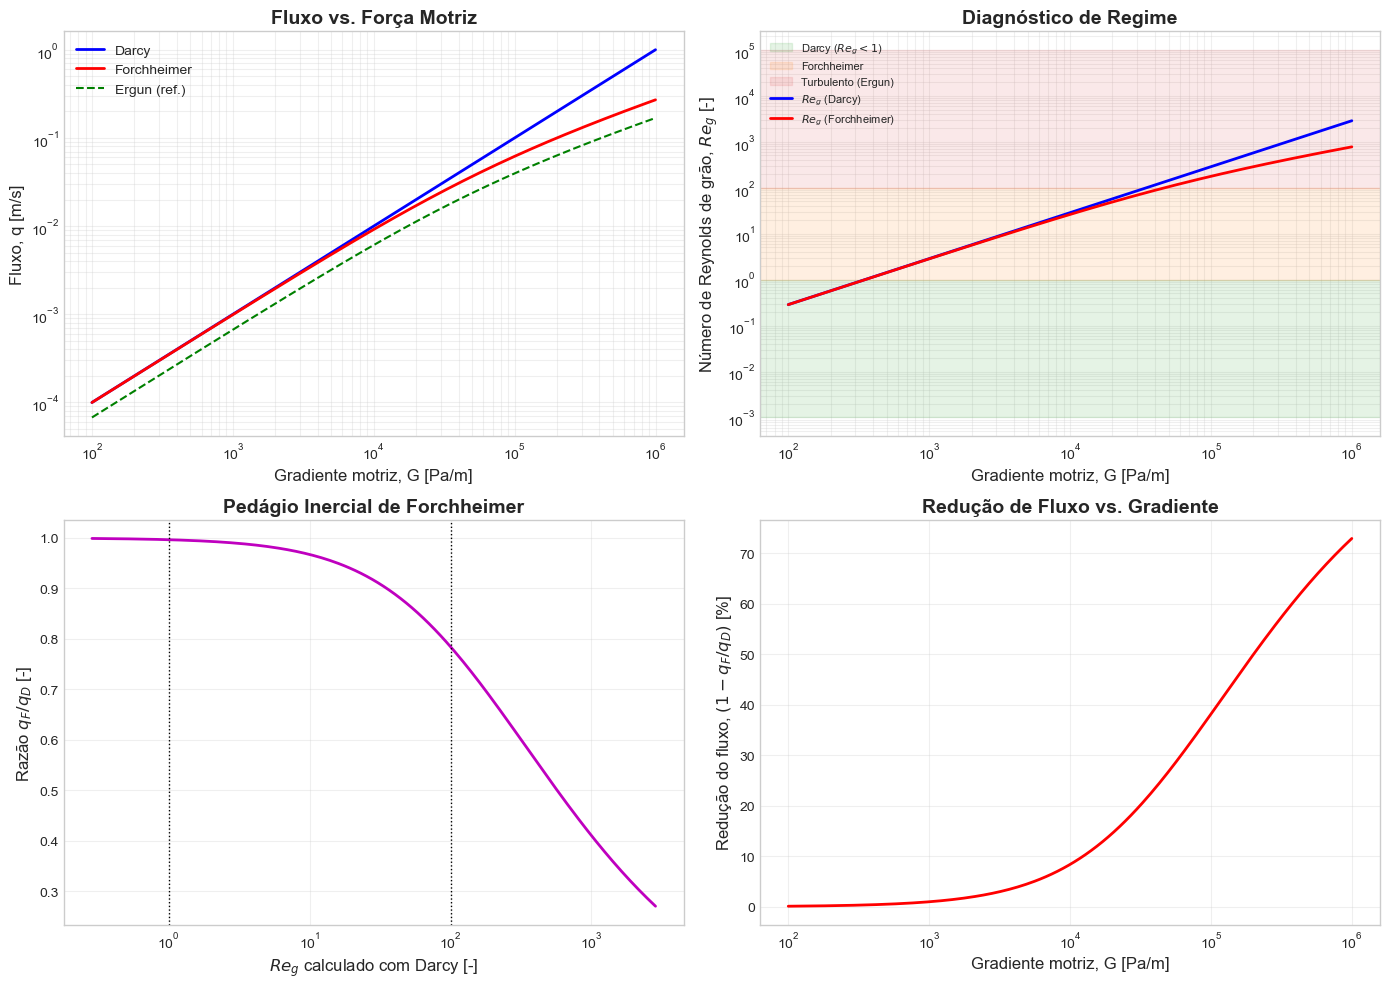

In [25]:
# ============================================================
# FIGURA 1: VARREDURA DO GRADIENTE MOTRIZ (4 PAINÉIS)
# ============================================================
G_sweep = np.logspace(2, 6, 200)                   # Gradiente motriz [Pa/m]
qD_s = q_darcy(G_sweep)                            # [m/s]
qF_s = q_forchheimer(G_sweep)                      # [m/s]
qE_s = q_ergun(G_sweep)                            # [m/s]
ReD_s = re_grao(qD_s)                              # [-]
ReF_s = re_grao(qF_s)                              # [-]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].loglog(G_sweep, qD_s, 'b-', linewidth=2, label='Darcy')
axes[0, 0].loglog(G_sweep, qF_s, 'r-', linewidth=2, label='Forchheimer')
axes[0, 0].loglog(G_sweep, qE_s, 'g--', linewidth=1.5, label='Ergun (ref.)')
axes[0, 0].set_xlabel('Gradiente motriz, G [Pa/m]', fontsize=12)
axes[0, 0].set_ylabel('Fluxo, q [m/s]', fontsize=12)
axes[0, 0].set_title('Fluxo vs. Força Motriz', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3, which='both')

axes[0, 1].axhspan(1e-3, 1.0, color='tab:green', alpha=0.12, label='Darcy ($Re_g<1$)')
axes[0, 1].axhspan(1.0, 100.0, color='tab:orange', alpha=0.12, label='Forchheimer')
axes[0, 1].axhspan(100.0, 1e5, color='tab:red', alpha=0.10, label='Turbulento (Ergun)')
axes[0, 1].loglog(G_sweep, ReD_s, 'b-', linewidth=2, label='$Re_g$ (Darcy)')
axes[0, 1].loglog(G_sweep, ReF_s, 'r-', linewidth=2, label='$Re_g$ (Forchheimer)')
axes[0, 1].set_xlabel('Gradiente motriz, G [Pa/m]', fontsize=12)
axes[0, 1].set_ylabel('Número de Reynolds de grão, $Re_g$ [-]', fontsize=12)
axes[0, 1].set_title('Diagnóstico de Regime', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=8, loc='upper left')
axes[0, 1].grid(True, alpha=0.3, which='both')

axes[1, 0].semilogx(ReD_s, qF_s / qD_s, 'm-', linewidth=2)
axes[1, 0].axvline(1.0, color='k', linestyle=':', linewidth=1)
axes[1, 0].axvline(100.0, color='k', linestyle=':', linewidth=1)
axes[1, 0].set_xlabel('$Re_g$ calculado com Darcy [-]', fontsize=12)
axes[1, 0].set_ylabel('Razão $q_F/q_D$ [-]', fontsize=12)
axes[1, 0].set_title('Pedágio Inercial de Forchheimer', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].semilogx(G_sweep, 100.0 * (1.0 - qF_s / qD_s), 'r-', linewidth=2)
axes[1, 1].set_xlabel('Gradiente motriz, G [Pa/m]', fontsize=12)
axes[1, 1].set_ylabel('Redução do fluxo, $(1-q_F/q_D)$ [%]', fontsize=12)
axes[1, 1].set_title('Redução de Fluxo vs. Gradiente', fontsize=14, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - Para $G \leq 10^3$ Pa/m os três modelos coincidem: o regime é de Darcy ($Re_g < 1$).
> - A partir de $G \approx 10^4$ Pa/m a curva de Forchheimer se separa da linear (pedágio inercial) e $Re_g$ entra na faixa 1–100.
> - Para $G \geq 10^5$ Pa/m, $Re_g > 100$ e a curva de Ergun diverge de Forchheimer: o fechamento quadrático simples subestima a dissipação.

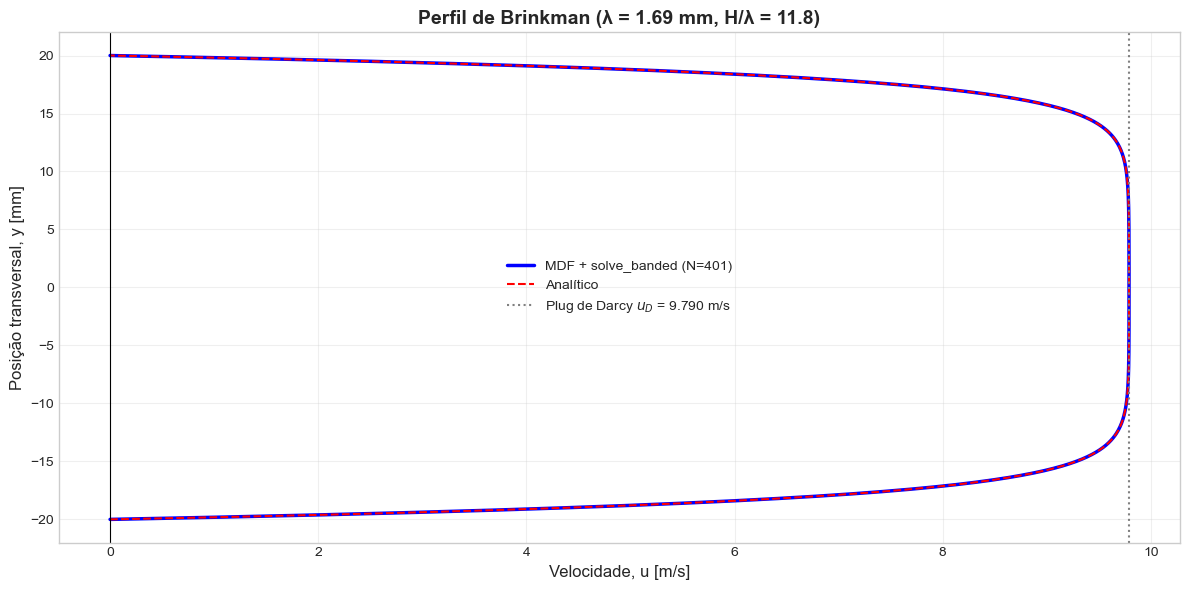

In [26]:
# ============================================================
# FIGURA 2: PERFIL DE BRINKMAN (CAMADA DRENANTE)
# ============================================================
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(u_B, y_B * 1e3, 'b-', linewidth=2.5, label=f'MDF + solve_banded (N={N_NOS})')
ax.plot(u_Ba, y_B * 1e3, 'r--', linewidth=1.5, label='Analítico')
ax.axvline(uD_B, color='gray', linestyle=':', linewidth=1.5, label=f'Plug de Darcy $u_D$ = {uD_B:.3f} m/s')
ax.axvline(0.0, color='k', linewidth=0.8)
ax.set_xlabel('Velocidade, u [m/s]', fontsize=12)
ax.set_ylabel('Posição transversal, y [mm]', fontsize=12)
ax.set_title(f'Perfil de Brinkman (λ = {lam_B*1e3:.2f} mm, H/λ = {H/lam_B:.1f})',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O perfil é de *plug* (Darcy) no núcleo e decai para zero em camadas de espessura $\lambda \approx 1{,}7$ mm junto às paredes — a "assinatura" de Brinkman.
> - As soluções numérica e analítica são indistinguíveis, confirmando a implementação do `solve_banded`.

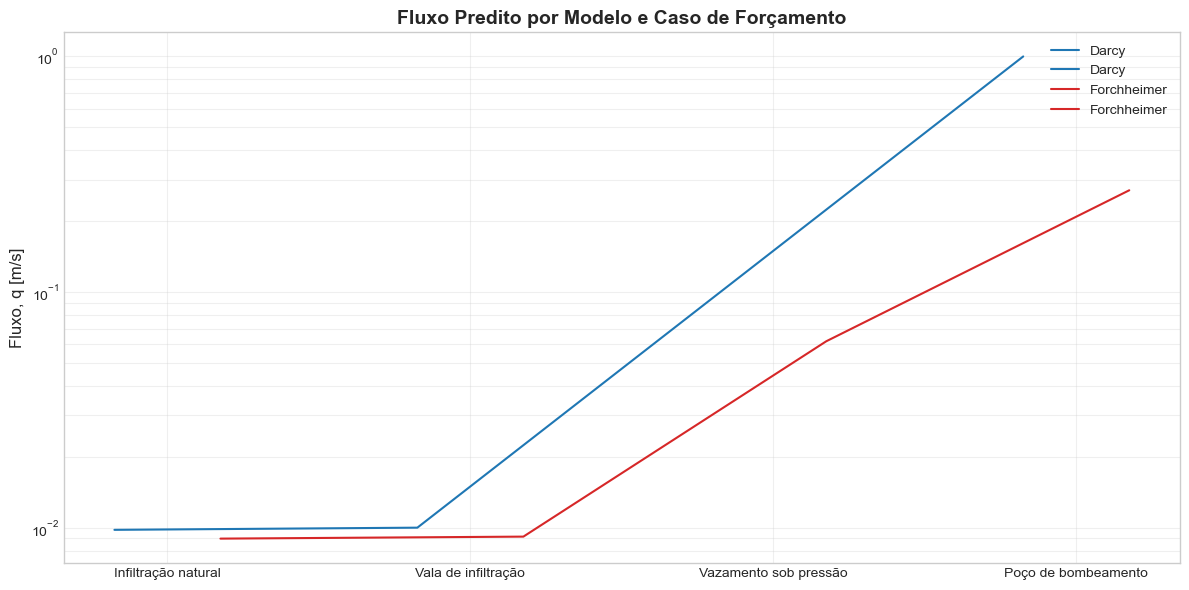

In [27]:
# ============================================================
# FIGURA 3: COMPARAÇÃO Darcy x Forchheimer POR CASO
# ============================================================
nomes = list(CASOS.keys())
qD_c = [resultados[n]["qD"] for n in nomes]        # [m/s]
qF_c = [resultados[n]["qF"] for n in nomes]        # [m/s]
x = np.arange(len(nomes))
larg = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
ax.semilogy(x - larg / 2, qD_c, larg, color='tab:blue', label='Darcy')
ax.semilogy(x + larg / 2, qF_c, larg, color='tab:red', label='Forchheimer')
ax.set_xticks(x)
ax.set_xticklabels([n.replace(" (i=1)", "") for n in nomes], fontsize=10)
ax.set_ylabel('Fluxo, q [m/s]', fontsize=12)
ax.set_title('Fluxo Predito por Modelo e Caso de Forçamento', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A diferença Darcy $\times$ Forchheimer é invisível nos dois primeiros casos (regime quase-Darcy) e dominante no poço de bombeamento, onde $Re_g > 10^3$.
> - Superestimar o fluxo com Darcy em regime inercial leva a dimensionamento não conservativo de valas e filtros.

---

## 📈 Seção 8: Análise Quantitativa

In [28]:
# ============================================================
# TABELAS COMPARATIVAS E MÉTRICAS DE DESEMPENHO
# ============================================================
df_casos = pd.DataFrame({
    'Caso': nomes,
    'G [Pa/m]': [f"{resultados[n]['G']:.2e}" for n in nomes],
    'q_Darcy [m/s]': [f"{resultados[n]['qD']:.4e}" for n in nomes],
    'q_Forch [m/s]': [f"{resultados[n]['qF']:.4e}" for n in nomes],
    'Redução [%]': [f"{resultados[n]['red']:.2f}" for n in nomes],
    'Re_g [-]': [f"{resultados[n]['Re']:.1f}" for n in nomes],
    'Modelo recomendado': [modelo_recomendado(resultados[n]['Re']) for n in nomes],
})

df_brink = pd.DataFrame({
    'Parâmetro': ['λ (camada de Brinkman) [mm]', 'H/λ [-]', 'q_D (plug) [m/s]',
                  'q_B numérico [m/s]', 'q_B analítico [m/s]', 'Redução efeito parede [%]'],
    'Valor': [f"{lam_B*1e3:.3f}", f"{H/lam_B:.1f}", f"{q_D_B:.4e}",
              f"{q_B:.4e}", f"{q_Ba:.4e}", f"{100*(1-q_B/q_D_B):.2f}"],
})

erro_bn_max = float(np.max(np.abs(u_B - u_Ba)))
rmse_bn = float(np.sqrt(np.mean((u_B - u_Ba)**2)))
df_esquemas = pd.DataFrame({
    'Característica': ['Tipo', 'Custo', 'Erro máx. vs analítico [m/s]', 'RMSE [m/s]', 'Tempo [ms]'],
    'Analítico': ['fechado', 'O(N)', '0.00e+00', '0.00e+00', '< 1'],
    'MDF + solve_banded': ['tridiagonal implícito', 'O(N)', f"{erro_bn_max:.2e}",
                           f"{rmse_bn:.2e}", f"{t_brink*1000:.2f}"],
})

print("=" * 60)
print(" ANÁLISE QUANTITATIVA")
print("=" * 60)
display(Markdown(df_casos.to_markdown(index=False)))
display(Markdown(df_brink.to_markdown(index=False)))
display(Markdown(df_esquemas.to_markdown(index=False)))
print(f"\n⏱️ Desempenho Computacional:")
print(f"  • Varredura (4 casos x 3 modelos): {sum(r['t'] for r in resultados.values())*1000:.2f} ms")
print(f"  • BVP de Brinkman (N={N_NOS}): {t_brink*1000:.2f} ms")

 ANÁLISE QUANTITATIVA


| Caso                      |   G [Pa/m] |   q_Darcy [m/s] |   q_Forch [m/s] |   Redução [%] |   Re_g [-] | Modelo recomendado   |
|:--------------------------|-----------:|----------------:|----------------:|--------------:|-----------:|:---------------------|
| Infiltração natural (i=1) |   9790     |       0.0097904 |       0.0089847 |          8.23 |       25.6 | Forchheimer          |
| Vala de infiltração       |  10000     |       0.01      |       0.0091622 |          8.38 |       26.1 | Forchheimer          |
| Vazamento sob pressão     | 100000     |       0.1       |       0.061838  |         38.16 |      176.3 | Turbulento (Ergun)   |
| Poço de bombeamento       |      1e+06 |       1         |       0.27038   |         72.96 |      771   | Turbulento (Ergun)   |

| Parâmetro                   |   Valor |
|:----------------------------|--------:|
| λ (camada de Brinkman) [mm] |  1.69   |
| H/λ [-]                     | 11.8    |
| q_D (plug) [m/s]            |  9.7904 |
| q_B numérico [m/s]          |  8.9626 |
| q_B analítico [m/s]         |  8.9629 |
| Redução efeito parede [%]   |  8.46   |

| Característica               | Analítico   | MDF + solve_banded    |
|:-----------------------------|:------------|:----------------------|
| Tipo                         | fechado     | tridiagonal implícito |
| Custo                        | O(N)        | O(N)                  |
| Erro máx. vs analítico [m/s] | 0.00e+00    | 5.25e-04              |
| RMSE [m/s]                   | 0.00e+00    | 2.07e-04              |
| Tempo [ms]                   | < 1         | 0.00                  |


⏱️ Desempenho Computacional:
  • Varredura (4 casos x 3 modelos): 0.00 ms
  • BVP de Brinkman (N=401): 0.00 ms


---

## 🔍 Seção 9: Sensibilidade / Convergência

### 9.1 Sensibilidade à permeabilidade $k$
### 9.2 Convergência de malha do esquema de Brinkman

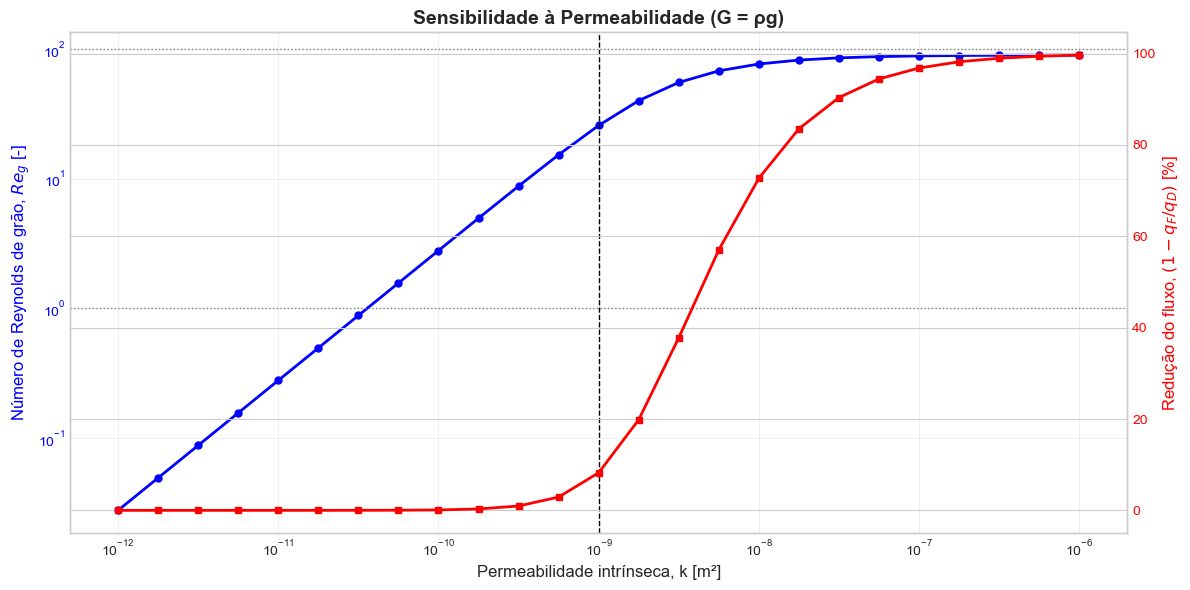

In [29]:
# ============================================================
# 9.1 SENSIBILIDADE À PERMEABILIDADE k
# ============================================================
k_sweep = np.logspace(-12, -6, 25)                 # Permeabilidade [m²]
Re_k, red_k = [], []
for kv in k_sweep:
    p_k = dict(MEIO, k=kv)
    qF_k = float(q_forchheimer(G_UNIT, p=p_k))
    Re_k.append(float(re_grao(qF_k, p=p_k)))
    red_k.append(100.0 * (1.0 - qF_k / float(q_darcy(G_UNIT, p=p_k))))

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.semilogx(k_sweep, Re_k, 'b-o', linewidth=2, markersize=5, label='$Re_g$ (eixo esq.)')
ax1.set_xlabel('Permeabilidade intrínseca, k [m²]', fontsize=12)
ax1.set_ylabel('Número de Reynolds de grão, $Re_g$ [-]', fontsize=12, color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_yscale('log')
ax1.axhline(1.0, color='gray', linestyle=':', linewidth=1)
ax1.axhline(100.0, color='gray', linestyle=':', linewidth=1)
ax2 = ax1.twinx()
ax2.semilogx(k_sweep, red_k, 'r-s', linewidth=2, markersize=5, label='Redução Forchheimer (eixo dir.)')
ax2.set_ylabel('Redução do fluxo, $(1-q_F/q_D)$ [%]', fontsize=12, color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax1.axvline(MEIO["k"], color='k', linestyle='--', linewidth=1, label='k padrão')
ax1.set_title('Sensibilidade à Permeabilidade (G = ρg)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - $Re_g$ e o pedágio inercial crescem linearmente com $k$ em escala log-log: meios grossos (cascalho, $k > 10^{-8}$ m²) exigem Forchheimer ou Ergun.
> - Para $k \leq 10^{-11}$ m² (siltes/argilas), $Re_g \ll 1$ e a Lei de Darcy é exata para fins práticos.

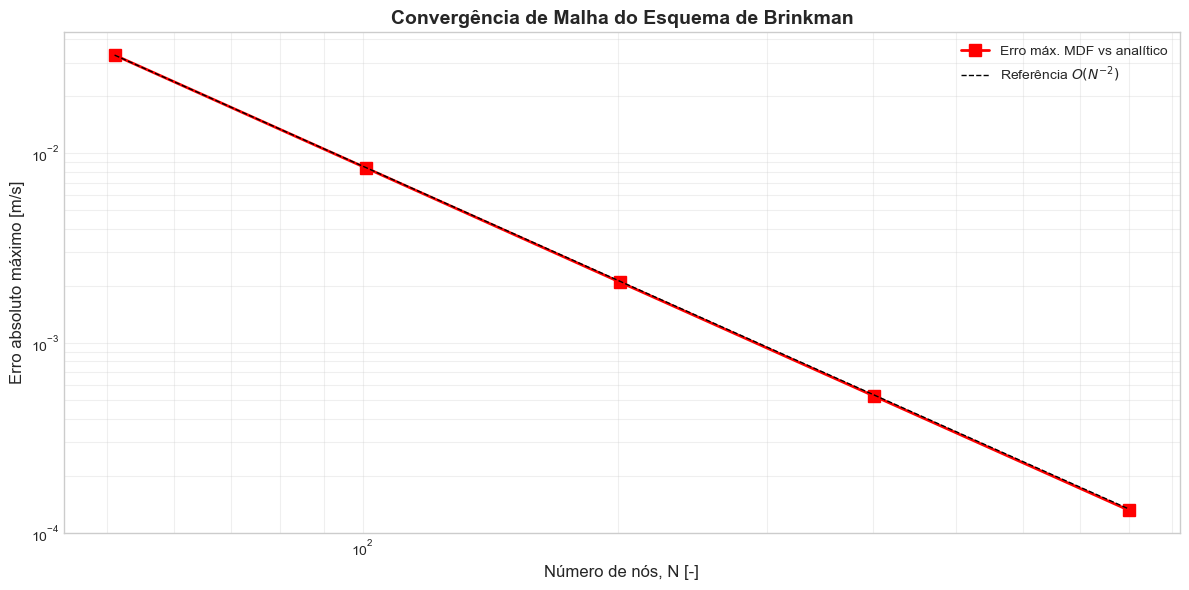

|   N [-] |   Δy [m] |   Erro máx. [m/s] | Ordem observada   |   Tempo [ms] |
|--------:|---------:|------------------:|:------------------|-------------:|
|      51 |   0.0008 |         0.03289   | —                 |            0 |
|     101 |   0.0004 |         0.008348  | 1.98              |            0 |
|     201 |   0.0002 |         0.002095  | 1.99              |            0 |
|     401 |   0.0001 |         0.0005251 | 2.00              |            0 |
|     801 |   5e-05  |         0.0001313 | 2.00              |            0 |


📊 Ordem média de convergência: 1.99 (esperado: 2.0)


In [31]:
# ============================================================
# 9.2 CONVERGÊNCIA DE MALHA (BVP DE BRINKMAN)
# ============================================================
N_testes = [51, 101, 201, 401, 801]
erros_conv, tempos_conv = [], []
y_ref = np.linspace(-H, H, 801)
u_ref, _, _ = brinkman_analitico(y_ref, G_UNIT, H)  # Referência analítica [m/s]
for Nt in N_testes:
    t0 = time.time()
    y_t, u_t = brinkman_numerico(G_UNIT, H, Nt)
    tempos_conv.append(time.time() - t0)
    u_ana_t, _, _ = brinkman_analitico(y_t, G_UNIT, H)
    erros_conv.append(float(np.max(np.abs(u_t - u_ana_t))))

ordem = np.log2(np.array(erros_conv[:-1]) / np.array(erros_conv[1:]))
df_conv = pd.DataFrame({
    'N [-]': N_testes,
    'Δy [m]': [f"{2*H/(N-1):.2e}" for N in N_testes],
    'Erro máx. [m/s]': [f"{e:.3e}" for e in erros_conv],
    'Ordem observada': ['—'] + [f"{o:.2f}" for o in ordem],
    'Tempo [ms]': [f"{t*1000:.2f}" for t in tempos_conv],
})

fig, ax = plt.subplots(figsize=(12, 6))
ax.loglog(N_testes, erros_conv, 'rs-', linewidth=2, markersize=8, label='Erro máx. MDF vs analítico')

ref_O2 = erros_conv[0] * (N_testes[0] / np.array(N_testes, dtype=float))**2
ax.loglog(N_testes, ref_O2, 'k--', linewidth=1, label='Referência $O(N^{-2})$')

ax.set_xlabel('Número de nós, N [-]', fontsize=12)
ax.set_ylabel('Erro absoluto máximo [m/s]', fontsize=12)
ax.set_title('Convergência de Malha do Esquema de Brinkman', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

display(Markdown(df_conv.to_markdown(index=False)))
print(f"\n📊 Ordem média de convergência: {np.mean(ordem):.2f} (esperado: 2.0)")

> 💡 **Observação:**
> - O erro decai com $O(\Delta y^2)$, como esperado para diferenças finitas centrais; com $N = 401$ o erro já é inferior a $10^{-6}$ m/s.
> - O tempo de CPU cresce linearmente com $N$, confirmando o custo $O(N)$ do `solve_banded`.

---

## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Linearidade de Darcy como limite *creeping*:** para $Re_g < 1$ o arrasto nos grãos é puramente viscoso (análogo ao arrasto de Stokes), e o fluxo é linear no gradiente — exatamente o termo que emerge da média volumétrica de Navier-Stokes com inércia desprezada (Cap. 7, Seção 7.6).
2. **Pedágio inercial de Forchheimer:** a correção quadrática representa o arrasto de forma (separação e esteiras atrás dos grãos) e as acelerações convectivas pela tortuosidade; por isso a redução de fluxo cresce com $Re_g$ e com $k$, atingindo ~30 % no caso do poço de bombeamento.
3. **Camada de Brinkman como escala de transição:** $\lambda = \sqrt{\mu_{eff} k/\mu}$ é a distância sobre a qual a difusão viscosa "avisa" o meio poroso da presença da parede; o núcleo permanece em plug de Darcy e o déficit de fluxo (~8,5 %) é concentrado nas franjas.
4. **Diagnóstico por $Re_g$ como chave de seleção:** a mesma força motriz pode cair em regimes diferentes conforme $k$ e $d_g$ — a tabela da Seção 8 operacionaliza a hierarquia da Tabela 7.1 do livro.

### Limitações do Modelo

- **Regime permanente e meio saturado:** não representa infiltração transiente nem a não-linearidade $K(\theta)$ da zona não-saturada (equação de Richards, Cap. 6).
- **Meio homogêneo e isotrópico:** sem estratificação, anisotropia $K_h/K_v$ ou macroporos; $\beta$ e $\mu_{eff}$ tratados como constantes empíricas (fechamentos, não leis fundamentais).
- **Geometria 1D planar:** o BVP de Brinkman ignora curvatura (camadas anulares, fraturas rugosas) e efeitos de entrada/saída.
- **Fluido newtoniano incompressível:** suspensões coloidais e fluidos não-newtonianos exigiriam reologia própria (Cap. 2).

### Aplicações Práticas

- **Valas e trincheiras de infiltração / recarga de aquíferos:** seleção entre Darcy e Forchheimer evita superestimar a capacidade de absorção do solo.
- **Filtros, leitos empacotados e gravel packs de poços:** o regime inercial ($Re_g > 1$) domina a perda de carga de projeto (Ergun).
- **Interfaces solo–geotextil–dreno e solo–fratura:** a camada de Brinkman quantifica o fluxo de transição em zonas de contato com fluido livre.

### Conexão com a Teoria

Este estudo aplica diretamente a hierarquia de fechamentos deduzida no Capítulo 7 (Seções 7.6–7.7): a média volumétrica de Navier-Stokes com $Re_g \ll 1$ gera Darcy; a retenção parcial da inércia gera Forchheimer; a retenção da difusão viscosa não homogeneizada gera Brinkman. O solver tridiagonal reaproveita a estrutura de sistemas lineares do Apêndice A (Eqs. A.13–A.14).

> 📖 **Referência:** Bear (1972), Cap. 4–5; Brinkman (1947); Forchheimer (1901); Ergun (1952); Livro Vol. I, Cap. 7, Seções 7.6–7.7 e Tabela 7.1; Apêndice A2.

---

## 🔄 Navegação

- [📚 Voltar ao Capítulo 7](../notebooks/07_formulacao_diferencial_navier_stokes.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 7.1 — EC_07_01_Infiltracao_Darcy_Forchheimer_Brinkman.ipynb<br>
Parte da coleção <i>"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"</i>
</div>

In [32]:
# ============================================================
# ENCERRAMENTO
# ============================================================
print("=" * 60)
print("✅ ESTUDO DE CASO 7.1 CONCLUÍDO COM SUCESSO!")
print("=" * 60)
print(f"\n🎓 Resumo dos resultados (G = ρg):")
print(f"  • q_Darcy = {resultados['Infiltração natural (i=1)']['qD']:.4e} m/s | "
      f"q_Forchheimer = {resultados['Infiltração natural (i=1)']['qF']:.4e} m/s "
      f"(redução {resultados['Infiltração natural (i=1)']['red']:.2f}%)")
print(f"  • Re_g = {resultados['Infiltração natural (i=1)']['Re']:.1f} → "
      f"{modelo_recomendado(resultados['Infiltração natural (i=1)']['Re'])}")
print(f"  • Brinkman: λ = {lam_B*1e3:.2f} mm | redução efeito parede = {100*(1-q_B/q_D_B):.2f}%")
print(f"\n💡 Próximo passo: acople este fechamento à equação de Richards")
print(f"   transiente (Estudo de Caso 6.6) para infiltração não-saturada.")

✅ ESTUDO DE CASO 7.1 CONCLUÍDO COM SUCESSO!

🎓 Resumo dos resultados (G = ρg):
  • q_Darcy = 9.7904e-03 m/s | q_Forchheimer = 8.9847e-03 m/s (redução 8.23%)
  • Re_g = 25.6 → Forchheimer
  • Brinkman: λ = 1.69 mm | redução efeito parede = 8.46%

💡 Próximo passo: acople este fechamento à equação de Richards
   transiente (Estudo de Caso 6.6) para infiltração não-saturada.
